In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge, LinearRegression
from evalu import cv_scores,plot_curve

In [2]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


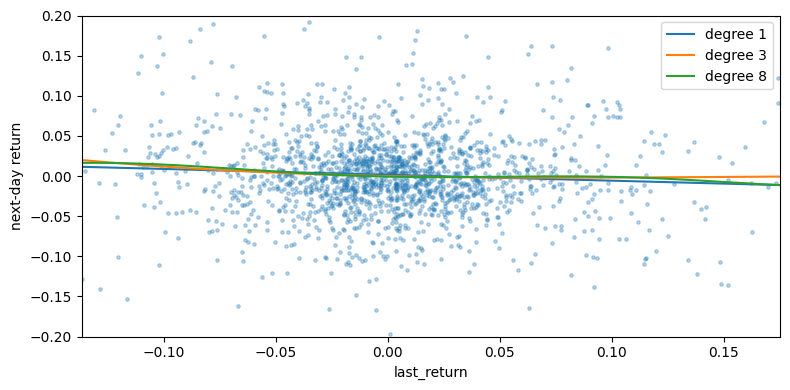

In [3]:
top = X_train.corrwith(y_reg).abs().idxmax()
x = X_train[top].values; yv = y_reg.values
xs = np.linspace(np.quantile(x, 0.01), np.quantile(x, 0.99), 200)
fig, ax = plt.subplots(figsize=(8, 4)); ax.scatter(x, yv, s=6, alpha=0.3)
for d in (1, 3, 8):
    ax.plot(xs, np.polyval(np.polyfit(x, yv, d), xs), label=f"degree {d}")
ax.set_xlim(xs[0], xs[-1]); ax.set_ylim(-0.2, 0.2); ax.set_xlabel(top); ax.set_ylabel("next-day return"); ax.legend()
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/poly_1d.png", dpi=130); plt.show()

In [4]:
from math import comb
n = X_train.shape[1]
print("degree 2 columns:", comb(n + 2, 2) - 1, "| degree 3 columns:", comb(n + 3, 3) - 1, "| rows available:", len(X_train))

degree 2 columns: 860 | degree 3 columns: 12340 | rows available: 1787


In [5]:
poly_ridge = Pipeline([("scaler", StandardScaler()), ("select", SelectKBest(f_regression, k=6)),
                       ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("model", Ridge(alpha=10))])

In [6]:
poly_ols = Pipeline([("scaler", StandardScaler()), ("select", SelectKBest(f_regression, k=6)),
                     ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("model", LinearRegression())])

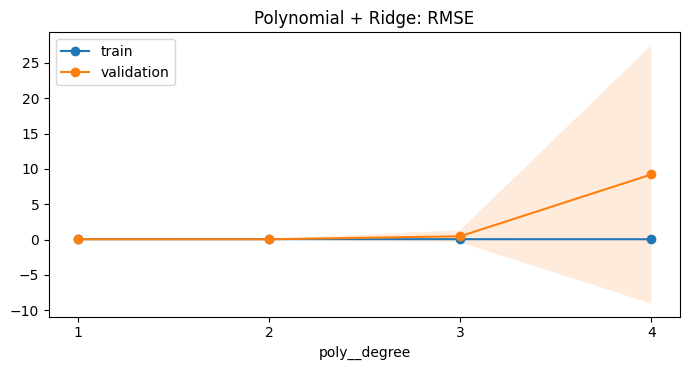

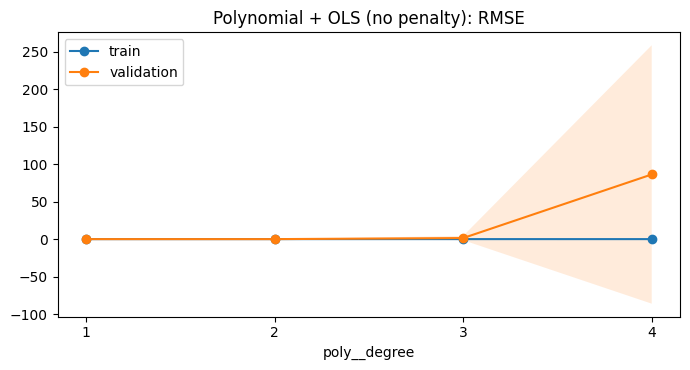

ridge                 ols           
         train validation    train validation
value                                        
1      0.06934    0.05060  0.06933    0.05068
2      0.06796    0.05264  0.06795    0.05220
3      0.06385    0.47380  0.06326    1.46085
4      0.05615    9.22340  0.05114   86.28831

In [7]:
degs = [1, 2, 3, 4]
dr = plot_curve(poly_ridge, X_train, y_reg, "poly__degree", degs, "neg_root_mean_squared_error", "Polynomial + Ridge: RMSE", "poly_degree_ridge.png", flip=True)
do = plot_curve(poly_ols, X_train, y_reg, "poly__degree", degs, "neg_root_mean_squared_error", "Polynomial + OLS (no penalty): RMSE", "poly_degree_ols.png", flip=True)
pd.concat({"ridge": dr.set_index("value"), "ols": do.set_index("value")}, axis=1).round(5)

Without the penalty the validation error blows up as degree increases; Ridge keeps it controlled.

In [8]:
r_reg = cv_scores(X_train, poly_ridge, y_reg, "regression")
print({k: round(v, 5) for k, v in r_reg.items() if k != "task"})
pd.DataFrame([{"model": "Polynomial Regression", **r_reg}]).to_csv("../../03.results/logs/model_results_polynomial.csv", index=False)

{'rmse': np.float64(0.05264), 'rmse_std': np.float64(0.0185), 'mae': np.float64(0.03799), 'mae_std': np.float64(0.01262), 'r2': np.float64(-0.11476), 'r2_std': np.float64(0.12822)}
